# LISS-IV Satellite Patch Dataset — Data Mining & Analytics
** TerraClear Project**

This notebook performs a comprehensive data mining analysis on 58,769 LISS-IV satellite image patches sourced from ISRO Bhoonidhi portal (Resourcesat-2/2A, Assam, North East India). Covers 8 analysis sections aligned with Data Mining: Concepts and Techniques (Han, Kamber & Pei, 3rd Ed.).

**Dataset:** 256×256 PNG patches | 3 channels: Red (Band 3), Green (Band 2), NIR (Band 4)

In [2]:
# Install the packages and import the libraries
!pip install scikit-image seaborn -q

import os
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
from pathlib import Path
from tqdm.notebook import tqdm

from skimage import exposure, feature, filters, color
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Set the input path and analysis options
PATCH_DIR   = "/kaggle/input/datasets/amritnoorsingh/isro-data-patches/lissiv_patches"
SAMPLE_N    = 5000   # patches to load for heavy analysis (adjust based on RAM)
VIZ_N       = 9      # patches shown in visual grids
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Plot style
plt.rcParams.update({
    'figure.facecolor': '#0f1117',
    'axes.facecolor':   '#1a1f2e',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#e6edf3',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#e6edf3',
    'grid.color':       '#21262d',
    'grid.alpha':       0.5,
    'axes.titlecolor':  '#e6edf3',
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
    'font.family':      'DejaVu Sans',
})

print(f'[✓] Setup complete')

[✓] Setup complete


In [3]:
# Load the image patches
all_files = sorted([f for f in os.listdir(PATCH_DIR) if f.endswith('.png')])
print(f'[✓] Total patches in dataset : {len(all_files):,}')

# Sample N patches for analysis
sample_files = random.sample(all_files, min(SAMPLE_N, len(all_files)))

def load_patch(fname, normalize=True):
    """Load a single patch as float32 numpy array (H, W, 3)."""
    img = Image.open(os.path.join(PATCH_DIR, fname)).convert('RGB')
    arr = np.array(img, dtype=np.float32)
    if normalize:
        arr = arr / 255.0
    return arr

def load_batch(files, normalize=True):
    """Load a list of patch files into a (N, H, W, 3) array."""
    patches = []
    for f in tqdm(files, desc='Loading patches'):
        try:
            patches.append(load_patch(f, normalize))
        except Exception:
            pass
    return np.stack(patches)

print(f'[✓] Loading {len(sample_files):,} sample patches...')
patches = load_batch(sample_files)
print(f'[✓] Loaded shape : {patches.shape}  | dtype: {patches.dtype}')
print(f'[✓] Value range  : [{patches.min():.3f}, {patches.max():.3f}]')

[✓] Total patches in dataset : 58,760
[✓] Loading 5,000 sample patches...


Loading patches:   0%|          | 0/5000 [00:00<?, ?it/s]

[✓] Loaded shape : (5000, 256, 256, 3)  | dtype: float32
[✓] Value range  : [0.000, 1.000]


## Section 1 — Pixel Intensity Statistics & Distribution
*Han et al. Ch. 2: Data Description — central tendency, dispersion, distribution shape*

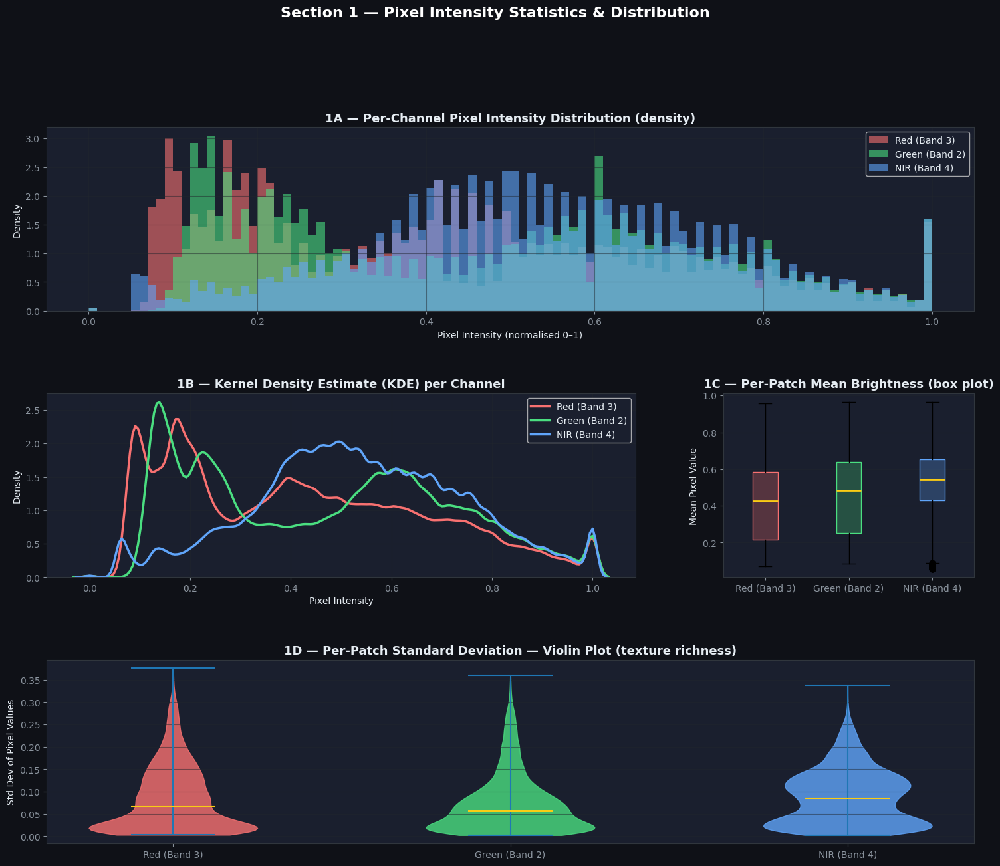


── Summary Statistics ──────────────────────────────────────
Red (Band 3)         | mean=0.423  std=0.086  min=0.071  max=0.959
Green (Band 2)       | mean=0.468  std=0.074  min=0.084  max=0.966
NIR (Band 4)         | mean=0.537  std=0.089  min=0.057  max=0.964


In [4]:
# Section 1: check pixel values in each band
CH_NAMES  = ['Red (Band 3)', 'Green (Band 2)', 'NIR (Band 4)']
CH_COLORS = ['#f87171', '#4ade80', '#60a5fa']

# Flatten all pixels per channel
px = [patches[:, :, :, c].ravel() for c in range(3)]

fig = plt.figure(figsize=(18, 14), facecolor='#0f1117')
fig.suptitle('Section 1 — Pixel Intensity Statistics & Distribution', fontsize=16, fontweight='bold', color='white', y=1.01)
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.45, wspace=0.35)

# 1A: Per-channel histogram
ax1 = fig.add_subplot(gs[0, :])
for i, (p, name, col) in enumerate(zip(px, CH_NAMES, CH_COLORS)):
    ax1.hist(p, bins=100, alpha=0.6, color=col, label=name, density=True)
ax1.set_title('1A — Per-Channel Pixel Intensity Distribution (density)')
ax1.set_xlabel('Pixel Intensity (normalised 0–1)')
ax1.set_ylabel('Density')
ax1.legend()
ax1.grid(True)

# 1B: KDE overlay
ax2 = fig.add_subplot(gs[1, 0:2])
for p, name, col in zip(px, CH_NAMES, CH_COLORS):
    sns.kdeplot(p[::50], ax=ax2, color=col, label=name, linewidth=2.5)
ax2.set_title('1B — Kernel Density Estimate (KDE) per Channel')
ax2.set_xlabel('Pixel Intensity')
ax2.legend()
ax2.grid(True)

# 1C: Box plot of per-patch mean per channel
patch_means = patches.mean(axis=(1,2))  # (N, 3)
ax3 = fig.add_subplot(gs[1, 2])
bp = ax3.boxplot([patch_means[:, i] for i in range(3)],
                  labels=CH_NAMES, patch_artist=True,
                  boxprops=dict(facecolor='#1a1f2e'),
                  medianprops=dict(color='#facc15', linewidth=2))
for patch, col in zip(bp['boxes'], CH_COLORS):
    patch.set_facecolor(col + '44')
    patch.set_edgecolor(col)
ax3.set_title('1C — Per-Patch Mean Brightness (box plot)')
ax3.set_ylabel('Mean Pixel Value')
ax3.grid(True, axis='y')

# 1D: Violin plot of per-patch std
patch_stds = patches.std(axis=(1,2))  # (N, 3)
ax4 = fig.add_subplot(gs[2, :])
vp = ax4.violinplot([patch_stds[:, i] for i in range(3)], positions=[1,2,3], showmedians=True)
for i, (body, col) in enumerate(zip(vp['bodies'], CH_COLORS)):
    body.set_facecolor(col + '55')
    body.set_edgecolor(col)
    body.set_alpha(0.8)
vp['cmedians'].set_color('#facc15')
ax4.set_xticks([1,2,3])
ax4.set_xticklabels(CH_NAMES)
ax4.set_title('1D — Per-Patch Standard Deviation — Violin Plot (texture richness)')
ax4.set_ylabel('Std Dev of Pixel Values')
ax4.grid(True, axis='y')

plt.tight_layout()
plt.savefig('section1_distributions.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# Summary statistics table
print('\n── Summary Statistics ──────────────────────────────────────')
for i, name in enumerate(CH_NAMES):
    print(f'{name:20s} | mean={patch_means[:,i].mean():.3f}  std={patch_stds[:,i].mean():.3f}  min={patch_means[:,i].min():.3f}  max={patch_means[:,i].max():.3f}')

## Section 2 — Spatial Texture Analysis
*Feature extraction using GLCM (Grey Level Co-occurrence Matrix) and Local Binary Patterns*

[..] Extracting texture features from 5000 patches...


GLCM:   0%|          | 0/5000 [00:00<?, ?it/s]

[✓] Feature matrix shape: (5000, 7)
        contrast  dissimilarity  homogeneity     energy  correlation  \
count  5000.0000      5000.0000    5000.0000  5000.0000    5000.0000   
mean      1.6016         0.6288       0.7581     0.2762       0.9329   
std       2.4117         0.5866       0.1769     0.1838       0.0853   
min       0.0038         0.0038       0.2554     0.0495       0.0392   
25%       0.1688         0.1683       0.6546     0.1185       0.9069   
50%       0.5081         0.3965       0.8125     0.2289       0.9556   
75%       1.6324         0.8323       0.9164     0.3891       0.9918   
max      25.2615         3.7378       0.9981     0.9961       0.9992   

       lbp_entropy  edge_density  
count    5000.0000     5000.0000  
mean        3.2586        0.0624  
std         0.2136        0.1072  
min         1.5873        0.0000  
25%         3.2358        0.0000  
50%         3.3297        0.0030  
75%         3.3908        0.0765  
max         3.4680        0.7030  


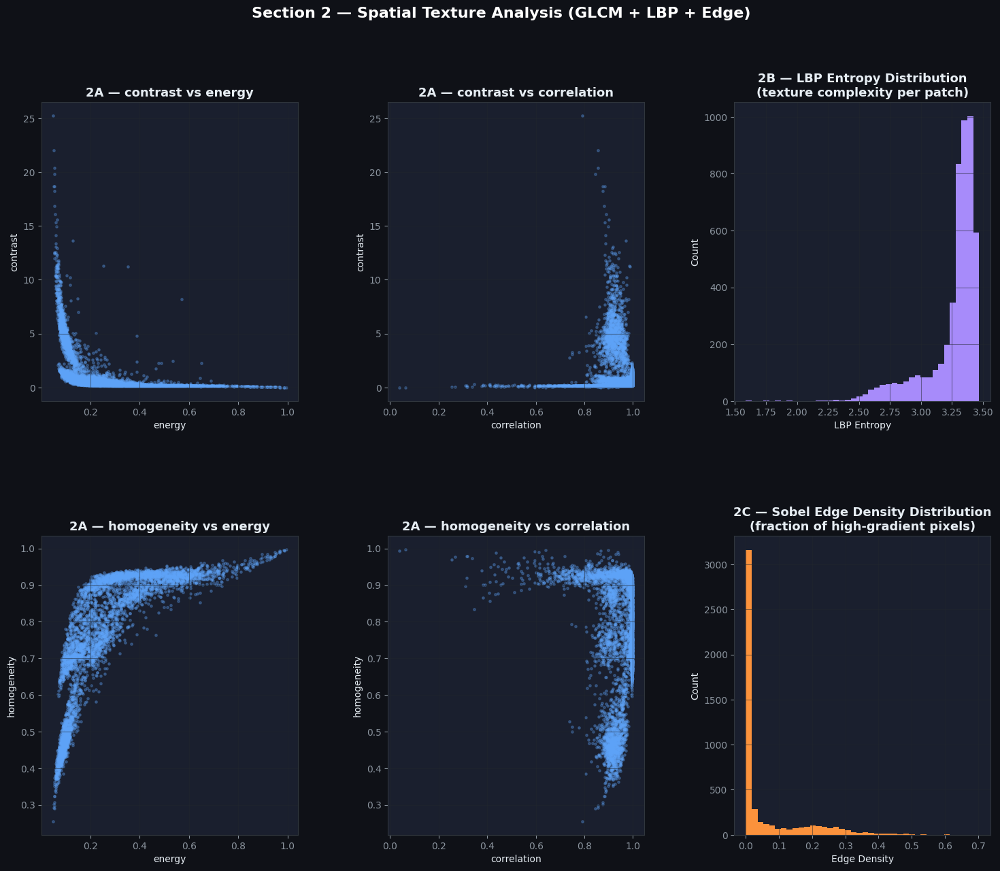

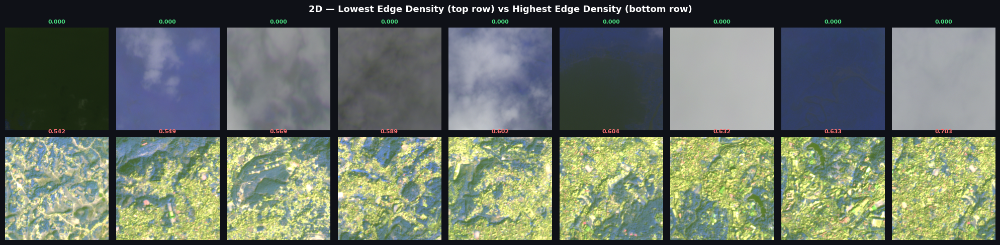

In [13]:
# Section 2: measure image texture
TEXTURE_N = min(5000, len(patches))  # GLCM is slow — use subset

def extract_glcm_features(patch_gray_uint8):
    """Extract contrast, dissimilarity, homogeneity, energy, correlation from GLCM."""
    glcm = graycomatrix(patch_gray_uint8, distances=[1], angles=[0, np.pi/4, np.pi/2],
                         levels=64, symmetric=True, normed=True)
    return {
        'contrast':      graycoprops(glcm, 'contrast').mean(),
        'dissimilarity': graycoprops(glcm, 'dissimilarity').mean(),
        'homogeneity':   graycoprops(glcm, 'homogeneity').mean(),
        'energy':        graycoprops(glcm, 'energy').mean(),
        'correlation':   graycoprops(glcm, 'correlation').mean(),
    }

def extract_lbp_entropy(patch_gray):
    """LBP histogram entropy — measures texture complexity."""
    lbp = local_binary_pattern(patch_gray, P=8, R=1, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=10, density=True)
    hist = hist[hist > 0]
    return -np.sum(hist * np.log2(hist))  # entropy

def extract_edge_density(patch_gray):
    """Sobel edge density — fraction of high-gradient pixels."""
    edges = filters.sobel(patch_gray)
    return (edges > 0.05).mean()

print(f'[..] Extracting texture features from {TEXTURE_N} patches...')
glcm_features = []
for patch in tqdm(patches[:TEXTURE_N], desc='GLCM'):
    gray_f = patch.mean(axis=2)                         # float [0,1]
    gray_u = (gray_f * 63).astype(np.uint8)             # uint8 [0,63] for 64-level GLCM
    feats  = extract_glcm_features(gray_u)
    feats['lbp_entropy']  = extract_lbp_entropy(gray_f)
    feats['edge_density'] = extract_edge_density(gray_f)
    glcm_features.append(feats)

import pandas as pd
tex_df = pd.DataFrame(glcm_features)
print(f'[✓] Feature matrix shape: {tex_df.shape}')
print(tex_df.describe().round(4))

# Plot the texture results
fig = plt.figure(figsize=(18, 14), facecolor='#0f1117')
fig.suptitle('Section 2 — Spatial Texture Analysis (GLCM + LBP + Edge)', fontsize=16, fontweight='bold', color='white')
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# 2A: Scatter matrix of top 4 GLCM features
feat_cols = ['contrast', 'homogeneity', 'energy', 'correlation']
feat_colors = ['#f87171', '#4ade80', '#60a5fa', '#facc15']
for ri, fc1 in enumerate(feat_cols[:2]):
    for ci, fc2 in enumerate(feat_cols[2:]):
        ax = fig.add_subplot(gs[ri, ci])
        ax.scatter(tex_df[fc2], tex_df[fc1], alpha=0.3, s=6, color='#60a5fa')
        ax.set_xlabel(fc2)
        ax.set_ylabel(fc1)
        ax.set_title(f'2A — {fc1} vs {fc2}')
        ax.grid(True)

# 2B: LBP entropy histogram
ax5 = fig.add_subplot(gs[0, 2])
ax5.hist(tex_df['lbp_entropy'], bins=40, color='#a78bfa', edgecolor='none')
ax5.set_title('2B — LBP Entropy Distribution\n(texture complexity per patch)')
ax5.set_xlabel('LBP Entropy')
ax5.set_ylabel('Count')
ax5.grid(True)

# 2C: Edge density distribution
ax6 = fig.add_subplot(gs[1, 2])
ax6.hist(tex_df['edge_density'], bins=40, color='#fb923c', edgecolor='none')
ax6.set_title('2C — Sobel Edge Density Distribution\n(fraction of high-gradient pixels)')
ax6.set_xlabel('Edge Density')
ax6.set_ylabel('Count')
ax6.grid(True)

plt.tight_layout()
plt.savefig('section2_texture.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# 2D: Sample patches ranked by edge density
fig2, axes = plt.subplots(2, 9, figsize=(20, 5), facecolor='#0f1117')
fig2.suptitle('2D — Lowest Edge Density (top row) vs Highest Edge Density (bottom row)', color='white', fontsize=13, fontweight='bold')
idx_sorted = tex_df['edge_density'].argsort().values
for i, idx in enumerate(idx_sorted[:9]):
    axes[0, i].imshow(patches[idx])
    axes[0, i].set_title(f'{tex_df["edge_density"].iloc[idx]:.3f}', fontsize=8, color='#4ade80')
    axes[0, i].axis('off')
for i, idx in enumerate(idx_sorted[-9:]):
    axes[1, i].imshow(patches[idx])
    axes[1, i].set_title(f'{tex_df["edge_density"].iloc[idx]:.3f}', fontsize=8, color='#f87171')
    axes[1, i].axis('off')
plt.tight_layout()
plt.savefig('section2_edge_samples.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

## Section 3 — Frequency Domain Analysis (FFT)
*Understanding spatial frequency content — smooth vs textured regions*

[..] Computing FFT power spectra...


FFT:   0%|          | 0/200 [00:00<?, ?it/s]

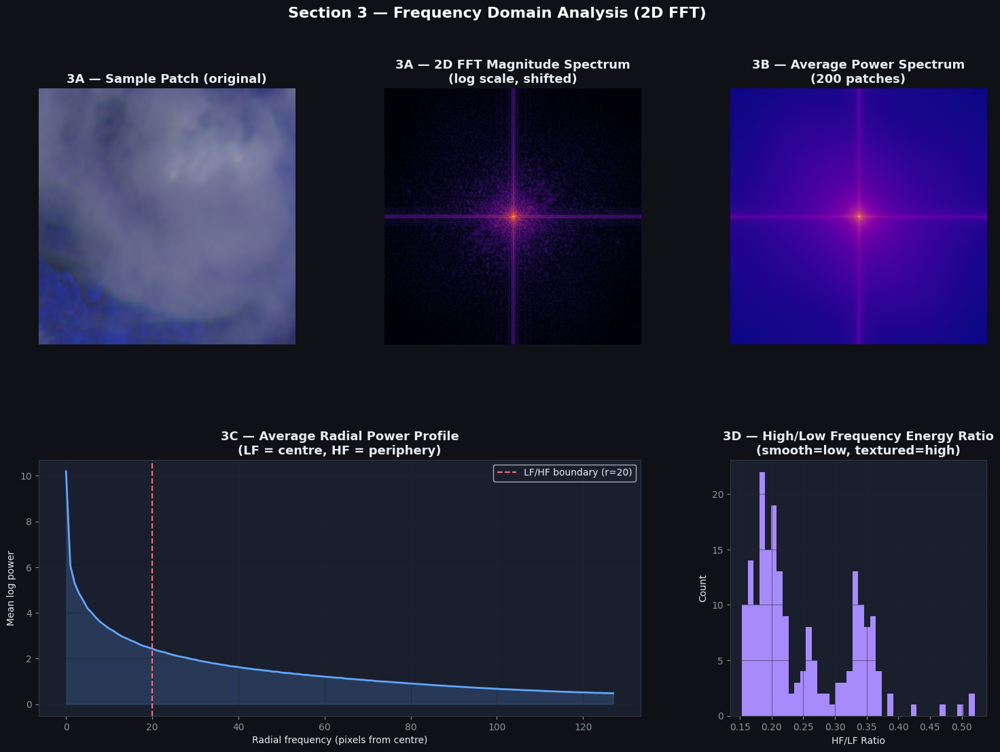

In [6]:
# Section 3: check image frequency patterns
FFT_N = min(200, len(patches))

def compute_power_spectrum(patch_gray):
    """2D FFT -> shifted magnitude spectrum."""
    fft     = np.fft.fft2(patch_gray)
    fft_sh  = np.fft.fftshift(fft)
    mag     = np.abs(fft_sh)
    return np.log1p(mag)  # log scale for visualisation

def radial_power_profile(power_spectrum):
    """Compute average power at each radial frequency."""
    h, w   = power_spectrum.shape
    cy, cx = h // 2, w // 2
    Y, X   = np.ogrid[:h, :w]
    R      = np.sqrt((X - cx)**2 + (Y - cy)**2).astype(int)
    r_max  = min(cx, cy)
    profile = [power_spectrum[R == r].mean() if (R == r).any() else 0 for r in range(r_max)]
    return np.array(profile)

print('[..] Computing FFT power spectra...')
spectra  = []
profiles = []
gray_patches = patches[:FFT_N].mean(axis=3) if patches.shape[-1] == 3 else patches[:FFT_N, :, :, 0]
for gp in tqdm(gray_patches, desc='FFT'):
    ps = compute_power_spectrum(gp)
    spectra.append(ps)
    profiles.append(radial_power_profile(ps))

avg_spectrum = np.mean(spectra, axis=0)
avg_profile  = np.mean(profiles, axis=0)

# High vs low frequency energy ratio
h, w = spectra[0].shape
cy, cx = h // 2, w // 2
hf_ratios = []
for ps in spectra:
    Y, X  = np.ogrid[:h, :w]
    R     = np.sqrt((X-cx)**2 + (Y-cy)**2)
    lf    = ps[R <= 20].mean()
    hf    = ps[R > 20].mean()
    hf_ratios.append(hf / (lf + 1e-8))

fig = plt.figure(figsize=(18, 12), facecolor='#0f1117')
fig.suptitle('Section 3 — Frequency Domain Analysis (2D FFT)', fontsize=16, fontweight='bold', color='white')
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# 3A: Sample patch + its spectrum
sample_idx = random.randint(0, FFT_N-1)
ax = fig.add_subplot(gs[0, 0])
ax.imshow(patches[sample_idx])
ax.set_title('3A — Sample Patch (original)')
ax.axis('off')

ax = fig.add_subplot(gs[0, 1])
ax.imshow(spectra[sample_idx], cmap='inferno')
ax.set_title('3A — 2D FFT Magnitude Spectrum\n(log scale, shifted)')
ax.axis('off')

# 3B: Average power spectrum across dataset
ax = fig.add_subplot(gs[0, 2])
ax.imshow(avg_spectrum, cmap='plasma')
ax.set_title(f'3B — Average Power Spectrum\n({FFT_N} patches)')
ax.axis('off')

# 3C: Average radial power profile
ax = fig.add_subplot(gs[1, 0:2])
ax.plot(avg_profile, color='#60a5fa', linewidth=2)
ax.fill_between(range(len(avg_profile)), avg_profile, alpha=0.2, color='#60a5fa')
ax.axvline(20, color='#f87171', linestyle='--', linewidth=1.5, label='LF/HF boundary (r=20)')
ax.set_title('3C — Average Radial Power Profile\n(LF = centre, HF = periphery)')
ax.set_xlabel('Radial frequency (pixels from centre)')
ax.set_ylabel('Mean log power')
ax.legend()
ax.grid(True)

# 3D: HF/LF ratio distribution
ax = fig.add_subplot(gs[1, 2])
ax.hist(hf_ratios, bins=40, color='#a78bfa', edgecolor='none')
ax.set_title('3D — High/Low Frequency Energy Ratio\n(smooth=low, textured=high)')
ax.set_xlabel('HF/LF Ratio')
ax.set_ylabel('Count')
ax.grid(True)

plt.tight_layout()
plt.savefig('section3_fft.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

## Section 4 — Histogram Equalization & Enhancement
*Data preprocessing — contrast enhancement, CLAHE, CDF visualisation*

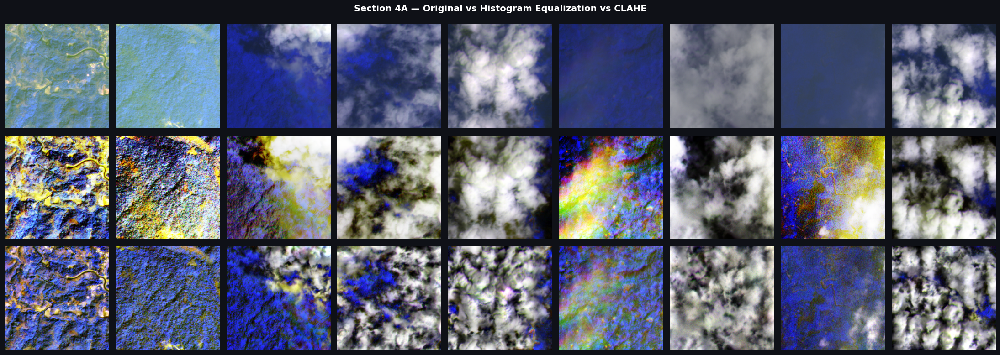

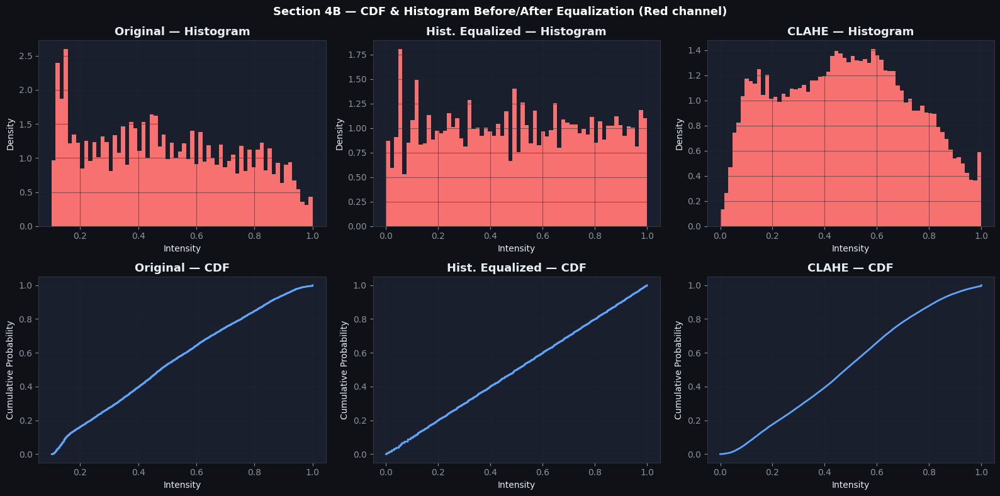

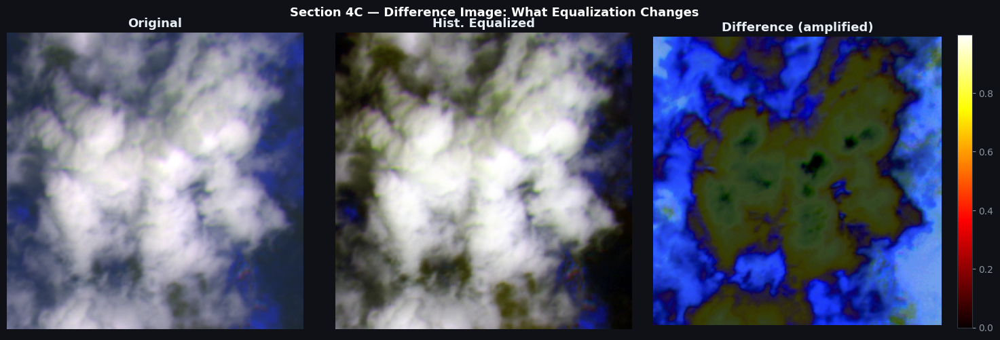

In [7]:
# Section 4: compare contrast enhancement methods
EQ_SAMPLES = random.sample(range(len(patches)), 9)

def enhance_patch(patch):
    """Returns original, hist-equalized, CLAHE versions."""
    orig  = patch.copy()
    # Per-channel histogram equalization
    eq = np.stack([exposure.equalize_hist(patch[:,:,c]) for c in range(3)], axis=2)
    # CLAHE — Contrast Limited Adaptive Histogram Equalization
    clahe = np.stack([exposure.equalize_adapthist(patch[:,:,c], clip_limit=0.03) for c in range(3)], axis=2)
    return orig, eq, clahe

# 4A: 3×9 grid: original | equalized | CLAHE
fig, axes = plt.subplots(3, 9, figsize=(22, 8), facecolor='#0f1117')
fig.suptitle('Section 4A — Original vs Histogram Equalization vs CLAHE', fontsize=14, fontweight='bold', color='white')
row_labels = ['Original', 'Hist. Equalized', 'CLAHE']
for col, idx in enumerate(EQ_SAMPLES):
    orig, eq, clahe = enhance_patch(patches[idx])
    for row, (img, label) in enumerate(zip([orig, eq, clahe], row_labels)):
        axes[row, col].imshow(np.clip(img, 0, 1))
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_ylabel(label, color='white', fontsize=10)
plt.tight_layout()
plt.savefig('section4a_equalization_grid.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# 4B: CDF before and after — single patch example
sample_patch = patches[EQ_SAMPLES[4]]
orig, eq, clahe = enhance_patch(sample_patch)

fig, axes = plt.subplots(2, 3, figsize=(16, 8), facecolor='#0f1117')
fig.suptitle('Section 4B — CDF & Histogram Before/After Equalization (Red channel)', fontsize=13, fontweight='bold', color='white')

titles = ['Original', 'Hist. Equalized', 'CLAHE']
for col, (img, title) in enumerate(zip([orig, eq, clahe], titles)):
    channel = img[:, :, 0].ravel()  # Red channel
    # Histogram
    axes[0, col].hist(channel, bins=64, color='#f87171', edgecolor='none', density=True)
    axes[0, col].set_title(f'{title} — Histogram')
    axes[0, col].set_xlabel('Intensity')
    axes[0, col].set_ylabel('Density')
    axes[0, col].grid(True)
    # CDF
    sorted_vals = np.sort(channel)
    cdf = np.arange(1, len(sorted_vals)+1) / len(sorted_vals)
    axes[1, col].plot(sorted_vals, cdf, color='#60a5fa', linewidth=2)
    axes[1, col].set_title(f'{title} — CDF')
    axes[1, col].set_xlabel('Intensity')
    axes[1, col].set_ylabel('Cumulative Probability')
    axes[1, col].grid(True)

plt.tight_layout()
plt.savefig('section4b_cdf.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# 4C: Difference image
fig, axes = plt.subplots(1, 3, figsize=(15, 5), facecolor='#0f1117')
fig.suptitle('Section 4C — Difference Image: What Equalization Changes', fontsize=13, fontweight='bold', color='white')
axes[0].imshow(np.clip(orig, 0, 1)); axes[0].set_title('Original'); axes[0].axis('off')
axes[1].imshow(np.clip(eq, 0, 1));   axes[1].set_title('Hist. Equalized'); axes[1].axis('off')
diff = np.abs(eq - orig)
diff_norm = (diff - diff.min()) / (diff.max() - diff.min() + 1e-8)
im = axes[2].imshow(diff_norm, cmap='hot')
axes[2].set_title('Difference (amplified)'); axes[2].axis('off')
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.savefig('section4c_diff.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

## Section 5 — Dimensionality Reduction & Clustering
*Han et al. Ch. 10–11: Cluster Analysis — K-Means, PCA, t-SNE*

[..] Building feature matrix...


Feature extraction:   0%|          | 0/1000 [00:00<?, ?it/s]

[✓] Feature matrix: (1000, 8)
[..] Running K-Means for elbow curve...


K-Means elbow:   0%|          | 0/9 [00:00<?, ?it/s]

[..] Running t-SNE (may take a minute)...


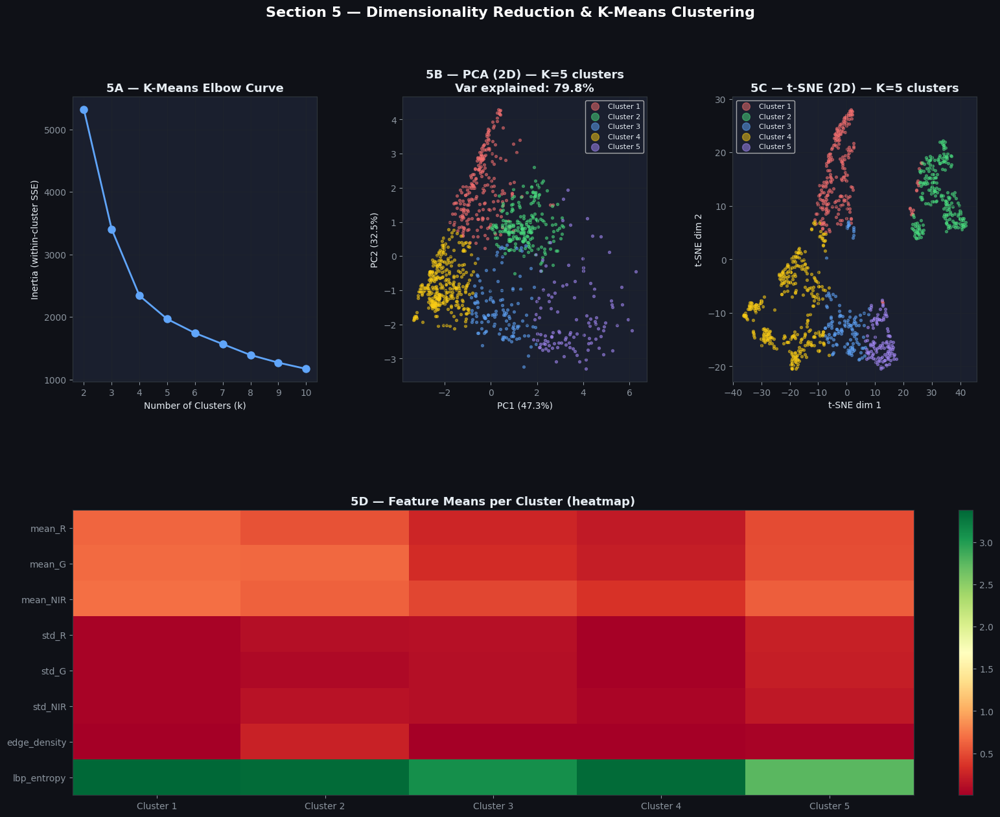

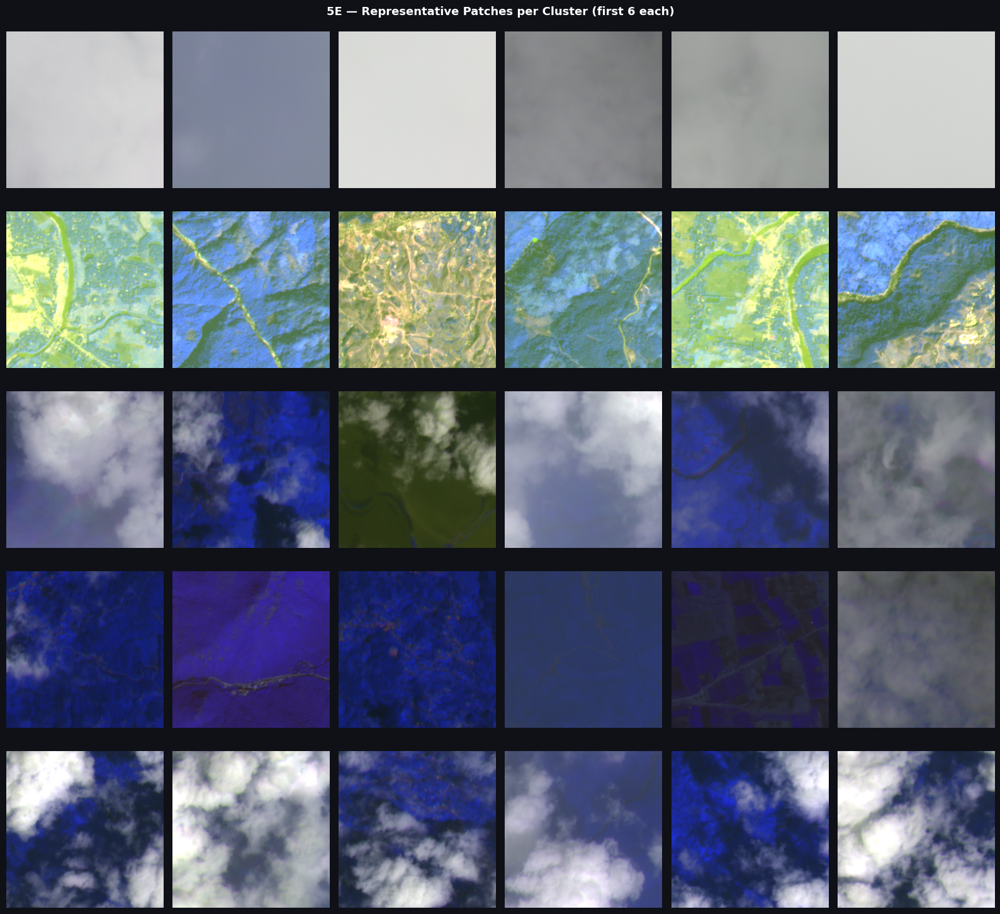

In [8]:
# Section 5: group patches by their features
CLUST_N = min(1000, len(patches))

# Build feature vector per patch: [mean_R, mean_G, mean_NIR, std_R, std_G, std_NIR, edge_density, lbp_entropy]
print('[..] Building feature matrix...')
feat_list = []
for p in tqdm(patches[:CLUST_N], desc='Feature extraction'):
    gray = p.mean(axis=2)
    edge = (filters.sobel(gray) > 0.05).mean()
    lbp  = local_binary_pattern(gray, P=8, R=1, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=10, density=True)
    hist     = hist[hist > 0]
    entropy  = -np.sum(hist * np.log2(hist))
    feat_list.append([
        p[:,:,0].mean(), p[:,:,1].mean(), p[:,:,2].mean(),  # means
        p[:,:,0].std(),  p[:,:,1].std(),  p[:,:,2].std(),   # stds
        edge, entropy
    ])

X = np.array(feat_list)
X_scaled = StandardScaler().fit_transform(X)
feat_names = ['mean_R','mean_G','mean_NIR','std_R','std_G','std_NIR','edge_density','lbp_entropy']
print(f'[✓] Feature matrix: {X.shape}')

# K-Means — elbow curve
print('[..] Running K-Means for elbow curve...')
inertias = []
K_range  = range(2, 11)
for k in tqdm(K_range, desc='K-Means elbow'):
    km = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=5)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

# Final clustering k=5
K_FINAL = 5
km_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_SEED, n_init=10)
labels   = km_final.fit_predict(X_scaled)

# PCA 2D
pca    = PCA(n_components=2, random_state=RANDOM_SEED)
X_pca  = pca.fit_transform(X_scaled)

# t-SNE 2D
print('[..] Running t-SNE (may take a minute)...')
tsne   = TSNE(n_components=2, random_state=RANDOM_SEED, perplexity=40, n_iter=800)
X_tsne = tsne.fit_transform(X_scaled)

CLUST_COLORS = ['#f87171','#4ade80','#60a5fa','#facc15','#a78bfa']

fig = plt.figure(figsize=(18, 14), facecolor='#0f1117')
fig.suptitle('Section 5 — Dimensionality Reduction & K-Means Clustering', fontsize=16, fontweight='bold', color='white')
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# 5A: Elbow curve
ax = fig.add_subplot(gs[0, 0])
ax.plot(list(K_range), inertias, 'o-', color='#60a5fa', linewidth=2, markersize=8)
ax.set_title('5A — K-Means Elbow Curve')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia (within-cluster SSE)')
ax.grid(True)

# 5B: PCA scatter
ax = fig.add_subplot(gs[0, 1])
for k in range(K_FINAL):
    mask = labels == k
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=8, alpha=0.5, color=CLUST_COLORS[k], label=f'Cluster {k+1}')
ax.set_title(f'5B — PCA (2D) — K={K_FINAL} clusters\nVar explained: {pca.explained_variance_ratio_.sum():.1%}')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
ax.legend(markerscale=3, fontsize=8)
ax.grid(True)

# 5C: t-SNE scatter
ax = fig.add_subplot(gs[0, 2])
for k in range(K_FINAL):
    mask = labels == k
    ax.scatter(X_tsne[mask, 0], X_tsne[mask, 1], s=8, alpha=0.5, color=CLUST_COLORS[k], label=f'Cluster {k+1}')
ax.set_title(f'5C — t-SNE (2D) — K={K_FINAL} clusters')
ax.set_xlabel('t-SNE dim 1')
ax.set_ylabel('t-SNE dim 2')
ax.legend(markerscale=3, fontsize=8)
ax.grid(True)

# 5D: Feature means per cluster (heatmap)
cluster_means = np.array([X[labels==k].mean(axis=0) for k in range(K_FINAL)])
ax = fig.add_subplot(gs[1, :])
im = ax.imshow(cluster_means.T, cmap='RdYlGn', aspect='auto')
ax.set_yticks(range(len(feat_names)))
ax.set_yticklabels(feat_names)
ax.set_xticks(range(K_FINAL))
ax.set_xticklabels([f'Cluster {k+1}' for k in range(K_FINAL)])
ax.set_title('5D — Feature Means per Cluster (heatmap)')
plt.colorbar(im, ax=ax, fraction=0.02)

plt.tight_layout()
plt.savefig('section5_clustering.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# 5E: Representative patches per cluster
fig, axes = plt.subplots(K_FINAL, 6, figsize=(16, K_FINAL*3), facecolor='#0f1117')
fig.suptitle('5E — Representative Patches per Cluster (first 6 each)', fontsize=13, fontweight='bold', color='white')
for k in range(K_FINAL):
    cluster_idx = np.where(labels == k)[0][:6]
    for col, idx in enumerate(cluster_idx):
        axes[k, col].imshow(patches[idx])
        axes[k, col].axis('off')
    axes[k, 0].set_ylabel(f'Cluster {k+1}', color=CLUST_COLORS[k], fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('section5_cluster_patches.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

## Section 6 — Spectral Indices (NDVI & NDWI)
*Domain feature engineering using LISS-IV's Green, Red, and NIR bands*

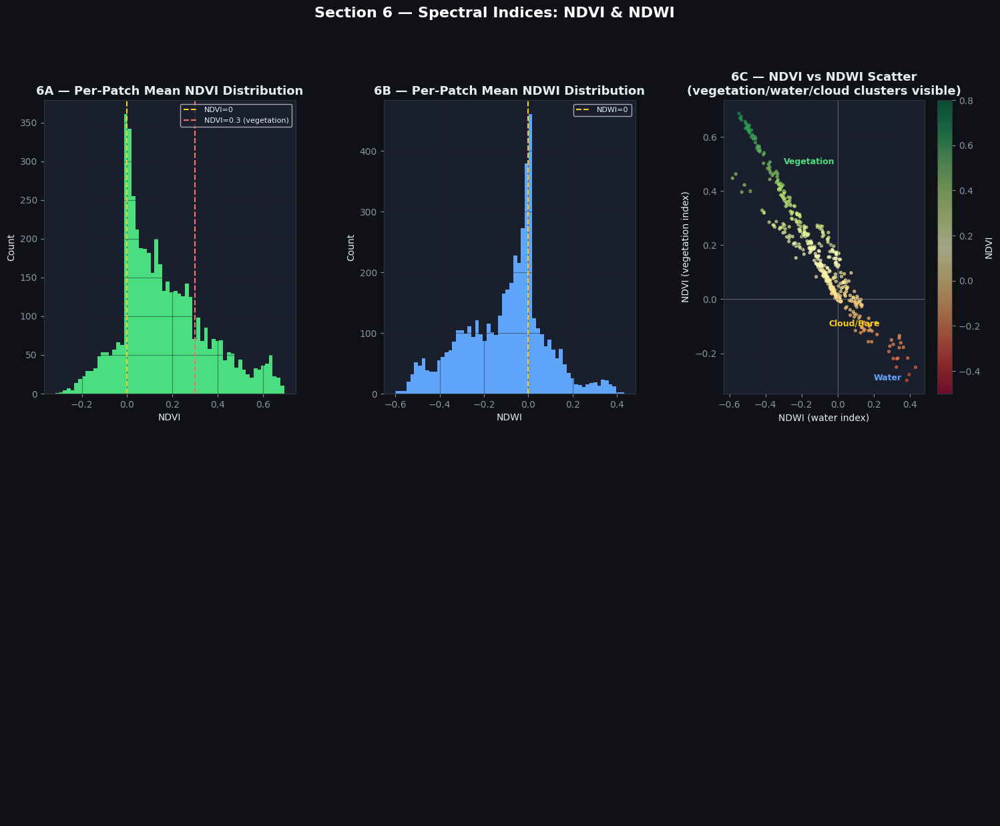

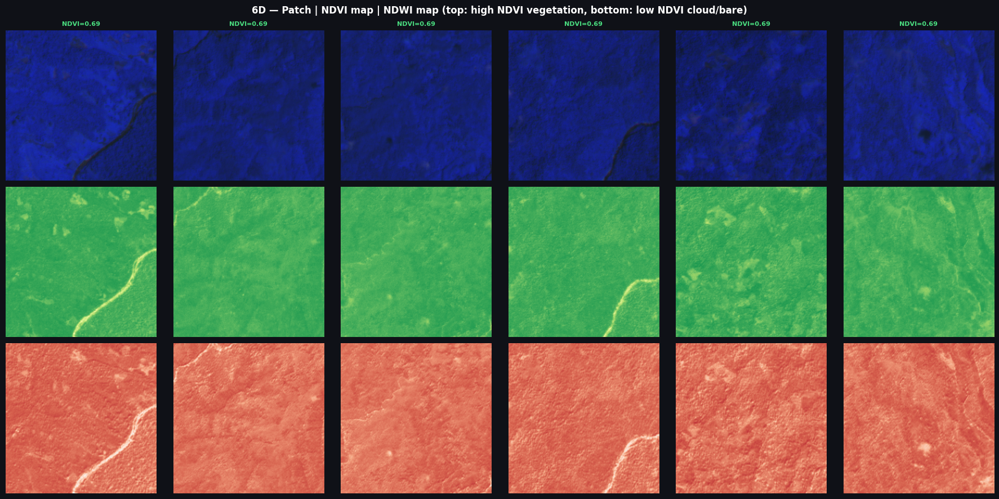

NDVI stats — mean: 0.162  std: 0.190  min: -0.317  max: 0.694
NDWI stats — mean: -0.101  std: 0.184  min: -0.601  max: 0.432


In [9]:
# Section 6: calculate spectral indices
# The channels are Red (Band 3), Green (Band 2), and NIR (Band 4).
R   = patches[:, :, :, 0].astype(np.float32) + 1e-8
Gr  = patches[:, :, :, 1].astype(np.float32) + 1e-8
NIR = patches[:, :, :, 2].astype(np.float32) + 1e-8

# NDVI = (NIR - Red) / (NIR + Red)  — vegetation index
NDVI = (NIR - R) / (NIR + R)          # (N, H, W)
# NDWI = (Green - NIR) / (Green + NIR) — water index
NDWI = (Gr - NIR) / (Gr + NIR)        # (N, H, W)

patch_ndvi = NDVI.mean(axis=(1, 2))   # per-patch mean NDVI
patch_ndwi = NDWI.mean(axis=(1, 2))   # per-patch mean NDWI

fig = plt.figure(figsize=(18, 14), facecolor='#0f1117')
fig.suptitle('Section 6 — Spectral Indices: NDVI & NDWI', fontsize=16, fontweight='bold', color='white')
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# 6A: NDVI distribution
ax = fig.add_subplot(gs[0, 0])
ax.hist(patch_ndvi, bins=60, color='#4ade80', edgecolor='none')
ax.axvline(0, color='#facc15', linestyle='--', linewidth=1.5, label='NDVI=0')
ax.axvline(0.3, color='#f87171', linestyle='--', linewidth=1.5, label='NDVI=0.3 (vegetation)')
ax.set_title('6A — Per-Patch Mean NDVI Distribution')
ax.set_xlabel('NDVI')
ax.set_ylabel('Count')
ax.legend(fontsize=8)
ax.grid(True)

# 6B: NDWI distribution
ax = fig.add_subplot(gs[0, 1])
ax.hist(patch_ndwi, bins=60, color='#60a5fa', edgecolor='none')
ax.axvline(0, color='#facc15', linestyle='--', linewidth=1.5, label='NDWI=0')
ax.set_title('6B — Per-Patch Mean NDWI Distribution')
ax.set_xlabel('NDWI')
ax.set_ylabel('Count')
ax.legend(fontsize=8)
ax.grid(True)

# 6C: NDVI vs NDWI scatter — surface type clusters
ax = fig.add_subplot(gs[0, 2])
sc = ax.scatter(patch_ndwi[:500], patch_ndvi[:500], c=patch_ndvi[:500],
                cmap='RdYlGn', s=8, alpha=0.6, vmin=-0.5, vmax=0.8)
ax.axhline(0, color='white', alpha=0.3, linewidth=0.8)
ax.axvline(0, color='white', alpha=0.3, linewidth=0.8)
ax.set_title('6C — NDVI vs NDWI Scatter\n(vegetation/water/cloud clusters visible)')
ax.set_xlabel('NDWI (water index)')
ax.set_ylabel('NDVI (vegetation index)')
ax.annotate('Vegetation', xy=(-.3, 0.5), color='#4ade80', fontsize=9, fontweight='bold')
ax.annotate('Water', xy=(0.2, -0.3), color='#60a5fa', fontsize=9, fontweight='bold')
ax.annotate('Cloud/Bare', xy=(-.05, -0.1), color='#facc15', fontsize=9, fontweight='bold')
plt.colorbar(sc, ax=ax, label='NDVI')
ax.grid(True)

# 6D: NDVI map on sample patches
NDVI_SAMPLES = 6
idx_high_ndvi = patch_ndvi.argsort()[-NDVI_SAMPLES:][::-1]
idx_low_ndvi  = patch_ndvi.argsort()[:NDVI_SAMPLES]

ax = fig.add_subplot(gs[1, :])
ax.axis('off')
fig2, axes2 = plt.subplots(3, NDVI_SAMPLES, figsize=(18, 9), facecolor='#0f1117')
fig2.suptitle('6D — Patch | NDVI map | NDWI map (top: high NDVI vegetation, bottom: low NDVI cloud/bare)',
              fontsize=12, fontweight='bold', color='white')
for col, idx in enumerate(idx_high_ndvi):
    axes2[0, col].imshow(patches[idx])
    axes2[0, col].set_title(f'NDVI={patch_ndvi[idx]:.2f}', fontsize=8, color='#4ade80')
    axes2[0, col].axis('off')
    im = axes2[1, col].imshow(NDVI[idx], cmap='RdYlGn', vmin=-1, vmax=1)
    axes2[1, col].axis('off')
    axes2[2, col].imshow(NDWI[idx], cmap='RdBu', vmin=-1, vmax=1)
    axes2[2, col].axis('off')
axes2[0, 0].set_ylabel('Patch', color='white', fontsize=9)
axes2[1, 0].set_ylabel('NDVI map', color='white', fontsize=9)
axes2[2, 0].set_ylabel('NDWI map', color='white', fontsize=9)
plt.tight_layout()
plt.savefig('section6_spectral_indices.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

print(f'NDVI stats — mean: {patch_ndvi.mean():.3f}  std: {patch_ndvi.std():.3f}  min: {patch_ndvi.min():.3f}  max: {patch_ndvi.max():.3f}')
print(f'NDWI stats — mean: {patch_ndwi.mean():.3f}  std: {patch_ndwi.std():.3f}  min: {patch_ndwi.min():.3f}  max: {patch_ndwi.max():.3f}')

## Section 7 — Cloud vs Clear Patch Analysis
*Basic classification using brightness threshold — Han et al. Ch. 8*

Brightness threshold: 0.65
Classified as cloudy : 1,009 (20.2%)
Classified as clear  : 3,991 (79.8%)


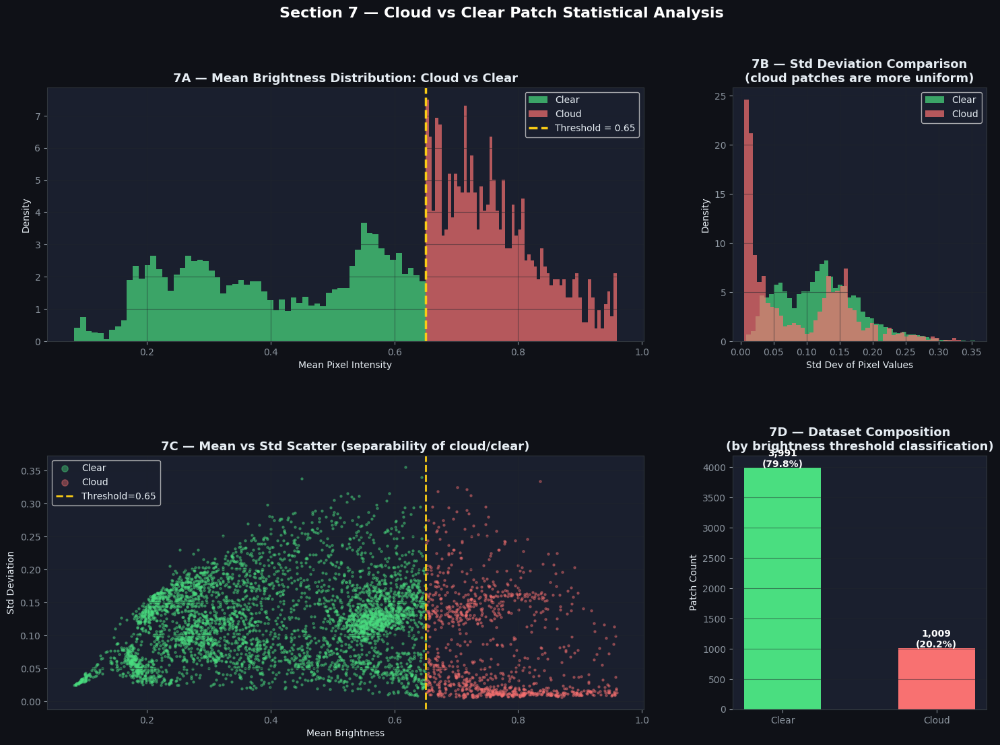

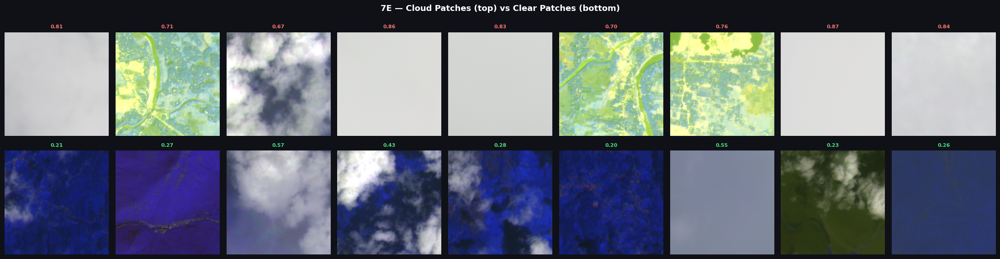

In [10]:
# Section 7: compare cloudy and clear patches
# Cloud patches are bright (high mean across all channels)
# Clear patches show natural variation (lower mean, higher std)

patch_means_all = patches.mean(axis=(1,2,3))   # overall mean brightness per patch
patch_stds_all  = patches.std(axis=(1,2,3))    # overall std per patch

# Simple brightness threshold to separate cloud from clear
THRESH = 0.65  # tune based on histogram
cloud_mask_pred = patch_means_all > THRESH
n_cloud = cloud_mask_pred.sum()
n_clear = (~cloud_mask_pred).sum()

print(f'Brightness threshold: {THRESH}')
print(f'Classified as cloudy : {n_cloud:,} ({n_cloud/len(patches)*100:.1f}%)')
print(f'Classified as clear  : {n_clear:,} ({n_clear/len(patches)*100:.1f}%)')

fig = plt.figure(figsize=(18, 12), facecolor='#0f1117')
fig.suptitle('Section 7 — Cloud vs Clear Patch Statistical Analysis', fontsize=16, fontweight='bold', color='white')
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# 7A: Brightness distribution with threshold
ax = fig.add_subplot(gs[0, 0:2])
ax.hist(patch_means_all[~cloud_mask_pred], bins=60, color='#4ade80', alpha=0.7, label='Clear', density=True)
ax.hist(patch_means_all[cloud_mask_pred],  bins=60, color='#f87171', alpha=0.7, label='Cloud', density=True)
ax.axvline(THRESH, color='#facc15', linewidth=2.5, linestyle='--', label=f'Threshold = {THRESH}')
ax.set_title('7A — Mean Brightness Distribution: Cloud vs Clear')
ax.set_xlabel('Mean Pixel Intensity')
ax.set_ylabel('Density')
ax.legend()
ax.grid(True)

# 7B: Std deviation comparison
ax = fig.add_subplot(gs[0, 2])
ax.hist(patch_stds_all[~cloud_mask_pred], bins=50, color='#4ade80', alpha=0.7, label='Clear', density=True)
ax.hist(patch_stds_all[cloud_mask_pred],  bins=50, color='#f87171', alpha=0.7, label='Cloud', density=True)
ax.set_title('7B — Std Deviation Comparison\n(cloud patches are more uniform)')
ax.set_xlabel('Std Dev of Pixel Values')
ax.set_ylabel('Density')
ax.legend()
ax.grid(True)

# 7C: Scatter — mean vs std (cloud region clearly separable)
ax = fig.add_subplot(gs[1, 0:2])
ax.scatter(patch_means_all[~cloud_mask_pred], patch_stds_all[~cloud_mask_pred],
           s=5, alpha=0.4, color='#4ade80', label='Clear')
ax.scatter(patch_means_all[cloud_mask_pred], patch_stds_all[cloud_mask_pred],
           s=5, alpha=0.4, color='#f87171', label='Cloud')
ax.axvline(THRESH, color='#facc15', linewidth=2, linestyle='--', label=f'Threshold={THRESH}')
ax.set_title('7C — Mean vs Std Scatter (separability of cloud/clear)')
ax.set_xlabel('Mean Brightness')
ax.set_ylabel('Std Deviation')
ax.legend(markerscale=3)
ax.grid(True)

# 7D: Cloud vs clear count bar
ax = fig.add_subplot(gs[1, 2])
bars = ax.bar(['Clear', 'Cloud'], [n_clear, n_cloud], color=['#4ade80', '#f87171'], edgecolor='none', width=0.5)
for bar, val in zip(bars, [n_clear, n_cloud]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            f'{val:,}\n({val/len(patches)*100:.1f}%)', ha='center', color='white', fontsize=10, fontweight='bold')
ax.set_title('7D — Dataset Composition\n(by brightness threshold classification)')
ax.set_ylabel('Patch Count')
ax.grid(True, axis='y')

plt.tight_layout()
plt.savefig('section7_cloud_clear.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# Visual grid of cloud vs clear samples
fig2, axes2 = plt.subplots(2, 9, figsize=(22, 6), facecolor='#0f1117')
fig2.suptitle('7E — Cloud Patches (top) vs Clear Patches (bottom)', fontsize=13, fontweight='bold', color='white')
cloud_idx = np.where(cloud_mask_pred)[0][:9]
clear_idx  = np.where(~cloud_mask_pred)[0][:9]
for col in range(9):
    axes2[0, col].imshow(patches[cloud_idx[col]])
    axes2[0, col].set_title(f'{patch_means_all[cloud_idx[col]]:.2f}', fontsize=8, color='#f87171')
    axes2[0, col].axis('off')
    axes2[1, col].imshow(patches[clear_idx[col]])
    axes2[1, col].set_title(f'{patch_means_all[clear_idx[col]]:.2f}', fontsize=8, color='#4ade80')
    axes2[1, col].axis('off')
plt.tight_layout()
plt.savefig('section7_cloud_clear_grid.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

## Section 8 — Patch Quality Assessment
*Composite quality scoring and dataset quality distribution*

[..] Computing quality scores...


Quality scoring:   0%|          | 0/5000 [00:00<?, ?it/s]

Quality score stats — mean: 0.579  std: 0.167  min: 0.176  max: 0.968
High quality (>0.7) : 1,472 (29.4%)
Low quality  (<0.3) : 284 (5.7%)


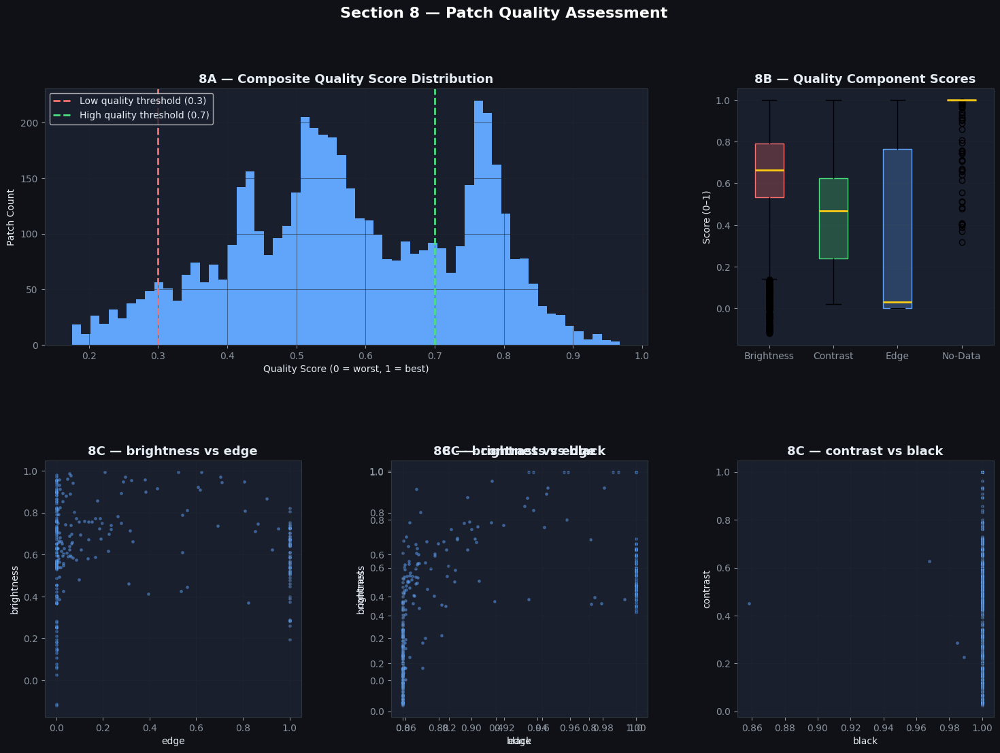

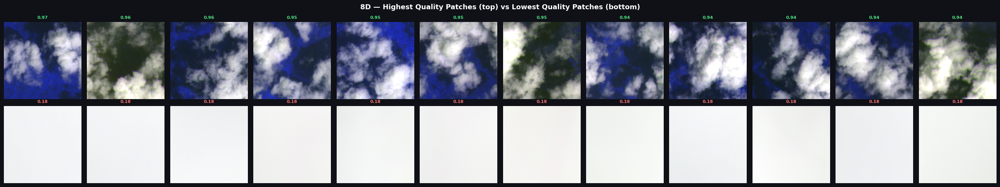

In [11]:
# Section 8: score patch quality
def compute_quality_score(patch):
    """
    Composite quality score (0-1, higher = better).
    Components:
      brightness_score : penalises too-dark or too-bright patches
      contrast_score   : rewards patches with high dynamic range
      edge_score       : rewards patches with real surface features
      black_penalty    : penalises NoData black regions
    """
    mean_b = patch.mean()
    std_b  = patch.std()
    gray   = patch.mean(axis=2)
    edge   = (filters.sobel(gray) > 0.05).mean()
    black_ratio = (patch.mean(axis=2) < 0.02).mean()

    brightness_score = 1.0 - abs(mean_b - 0.4) * 2   # peaks at mean=0.4
    contrast_score   = min(std_b * 4, 1.0)            # rewards high std
    edge_score       = min(edge * 10, 1.0)            # rewards edges
    black_penalty    = 1.0 - black_ratio * 5          # penalises black

    score = (
        0.30 * brightness_score +
        0.25 * contrast_score   +
        0.25 * edge_score       +
        0.20 * black_penalty
    )
    return max(0.0, min(1.0, score)), brightness_score, contrast_score, edge_score, black_penalty

print('[..] Computing quality scores...')
scores_all = [compute_quality_score(p) for p in tqdm(patches, desc='Quality scoring')]
q_total, q_bright, q_contrast, q_edge, q_black = zip(*scores_all)
q_total   = np.array(q_total)
q_bright  = np.array(q_bright)
q_contrast= np.array(q_contrast)
q_edge    = np.array(q_edge)
q_black   = np.array(q_black)

print(f'Quality score stats — mean: {q_total.mean():.3f}  std: {q_total.std():.3f}  min: {q_total.min():.3f}  max: {q_total.max():.3f}')
print(f'High quality (>0.7) : {(q_total > 0.7).sum():,} ({(q_total > 0.7).mean()*100:.1f}%)')
print(f'Low quality  (<0.3) : {(q_total < 0.3).sum():,} ({(q_total < 0.3).mean()*100:.1f}%)')

fig = plt.figure(figsize=(18, 12), facecolor='#0f1117')
fig.suptitle('Section 8 — Patch Quality Assessment', fontsize=16, fontweight='bold', color='white')
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# 8A: Overall quality histogram
ax = fig.add_subplot(gs[0, 0:2])
ax.hist(q_total, bins=60, color='#60a5fa', edgecolor='none')
ax.axvline(0.3, color='#f87171', linewidth=2, linestyle='--', label='Low quality threshold (0.3)')
ax.axvline(0.7, color='#4ade80', linewidth=2, linestyle='--', label='High quality threshold (0.7)')
ax.set_title('8A — Composite Quality Score Distribution')
ax.set_xlabel('Quality Score (0 = worst, 1 = best)')
ax.set_ylabel('Patch Count')
ax.legend()
ax.grid(True)

# 8B: Component scores box plot
ax = fig.add_subplot(gs[0, 2])
comp_data  = [q_bright, q_contrast.clip(0,1), q_edge.clip(0,1), q_black.clip(0,1)]
comp_names = ['Brightness', 'Contrast', 'Edge', 'No-Data']
bp = ax.boxplot(comp_data, labels=comp_names, patch_artist=True,
                medianprops=dict(color='#facc15', linewidth=2))
for patch, col in zip(bp['boxes'], ['#f87171','#4ade80','#60a5fa','#a78bfa']):
    patch.set_facecolor(col + '44')
    patch.set_edgecolor(col)
ax.set_title('8B — Quality Component Scores')
ax.set_ylabel('Score (0–1)')
ax.grid(True, axis='y')

# 8C: Scatter matrix of quality components
for i, (c1, n1) in enumerate([('brightness',q_bright), ('contrast',q_contrast)]):
    for j, (c2, n2) in enumerate([('edge',q_edge), ('black',q_black)]):
        ax = fig.add_subplot(gs[1, i*2+j-(i*1)])
        ax.scatter(n2[:300], n1[:300], s=6, alpha=0.4, color='#60a5fa')
        ax.set_xlabel(c2)
        ax.set_ylabel(c1)
        ax.set_title(f'8C — {c1} vs {c2}')
        ax.grid(True)
        if i*2+j-(i*1) >= 2: break

plt.tight_layout()
plt.savefig('section8_quality.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

# 8D: Top and bottom patches by quality
fig2, axes2 = plt.subplots(2, 12, figsize=(26, 5), facecolor='#0f1117')
fig2.suptitle('8D — Highest Quality Patches (top) vs Lowest Quality Patches (bottom)', fontsize=13, fontweight='bold', color='white')
top_idx = q_total.argsort()[-12:][::-1]
bot_idx = q_total.argsort()[:12]
for col in range(12):
    axes2[0, col].imshow(patches[top_idx[col]])
    axes2[0, col].set_title(f'{q_total[top_idx[col]]:.2f}', fontsize=8, color='#4ade80')
    axes2[0, col].axis('off')
    axes2[1, col].imshow(patches[bot_idx[col]])
    axes2[1, col].set_title(f'{q_total[bot_idx[col]]:.2f}', fontsize=8, color='#f87171')
    axes2[1, col].axis('off')
plt.tight_layout()
plt.savefig('section8_quality_grid.png', dpi=150, bbox_inches='tight', facecolor='#0f1117')
plt.show()

## Final Summary

In [12]:
# Print a summary of the results
print('  LISS-IV Dataset Analysis — Summary')
print(f'  Total patches in dataset       : {len(all_files):,}')
print(f'  Patches analysed               : {len(patches):,}')
print(f'  Patch resolution               : 256 × 256 px')
print(f'  Channels                       : Red, Green, NIR')
print()
print('  Section 1 — Pixel Stats')
for i, name in enumerate(CH_NAMES):
    print(f'    {name:20s} | mean={patch_means[:,i].mean():.3f}  std={patch_stds[:,i].mean():.3f}')
print()
print('  Section 2 — Texture')
print(f'    Avg GLCM contrast              : {tex_df["contrast"].mean():.3f}')
print(f'    Avg LBP entropy                : {tex_df["lbp_entropy"].mean():.3f}')
print(f'    Avg edge density               : {tex_df["edge_density"].mean():.4f}')
print()
print('  Section 5 — Clustering')
for k in range(K_FINAL):
    print(f'    Cluster {k+1}                      : {(labels==k).sum():,} patches')
print()
print('  Section 6 — Spectral Indices')
print(f'    Mean NDVI                      : {patch_ndvi.mean():.3f}')
print(f'    Mean NDWI                      : {patch_ndwi.mean():.3f}')
print()
print('  Section 7 — Cloud Detection')
print(f'    Cloudy patches (thresh={THRESH}) : {n_cloud:,} ({n_cloud/len(patches)*100:.1f}%)')
print(f'    Clear patches                  : {n_clear:,} ({n_clear/len(patches)*100:.1f}%)')
print()
print('  Section 8 — Quality')
print(f'    Mean quality score             : {q_total.mean():.3f}')
print(f'    High quality (>0.7)            : {(q_total>0.7).sum():,} ({(q_total>0.7).mean()*100:.1f}%)')
print('  Saved figures:')
for fig_name in ['section1_distributions','section2_texture','section2_edge_samples',
                  'section3_fft','section4a_equalization_grid','section4b_cdf',
                  'section4c_diff','section5_clustering','section5_cluster_patches',
                  'section6_spectral_indices','section7_cloud_clear',
                  'section7_cloud_clear_grid','section8_quality','section8_quality_grid']:
    print(f'    /kaggle/working/{fig_name}.png')


  LISS-IV Dataset Analysis — Summary
  Total patches in dataset       : 58,760
  Patches analysed               : 5,000
  Patch resolution               : 256 × 256 px
  Channels                       : Red, Green, NIR

  Section 1 — Pixel Stats
    Red (Band 3)         | mean=0.423  std=0.086
    Green (Band 2)       | mean=0.468  std=0.074
    NIR (Band 4)         | mean=0.537  std=0.089

  Section 2 — Texture
    Avg GLCM contrast              : 1.526
    Avg LBP entropy                : 3.260
    Avg edge density               : 0.0585

  Section 5 — Clustering
    Cluster 1                      : 225 patches
    Cluster 2                      : 215 patches
    Cluster 3                      : 125 patches
    Cluster 4                      : 323 patches
    Cluster 5                      : 112 patches

  Section 6 — Spectral Indices
    Mean NDVI                      : 0.162
    Mean NDWI                      : -0.101

  Section 7 — Cloud Detection
    Cloudy patches (thresh=0.65) 